# Comparación nacional de tres estimaciones de $R_t$ para varicela

Este cuaderno compara tres rutas del mismo proyecto: [notificaciones agregadas por semana](02_rt_nacional.ipynb), [notificaciones por día](05_rt_nacional_diario.ipynb) e [inicio de síntomas por día](06_rt_nacional_inicio_sintomas.ipynb). Las tres usan la previa Gamma de forma 1 y tasa 0,2, los momentos seriales de Simpson (media 14,1 y desviación estándar 2,4 días) y una ventana nominal de 14 días. La ruta semanal reconstruye conteos diarios a partir de totales por semana; las otras dos usan fechas individuales. En la tercera, `INI_SIN` es la fecha de inicio de síntomas **consignada retrospectivamente**, con faltantes. Ninguna ruta observa infecciones ni estima un efecto causal de la vacuna.

**Fuentes reproducibles:** [`rt_national_weekly.csv`](../docs/data_processed/numero_reproductivo/rt_national_weekly.csv), [`rt_national_daily.csv`](../docs/data_processed/numero_reproductivo/rt_national_daily.csv) y [`rt_national_symptom_daily.csv`](../docs/data_processed/numero_reproductivo/rt_national_symptom_daily.csv). Los dos últimos se generan desde los [CSV individuales](../data/sivigila/csv/); la serie semanal se deriva de los conteos del [Parquet por notificación](../data/sivigila_integrado_notification_semanal_municipal.parquet/). El [Parquet por inicio de síntomas](../data/sivigila_integrado_symptom_semanal_municipal.parquet/) sirve para reconciliar la tercera ruta. Véanse los cuadernos originales para los filtros, la discretización serial, la auditoría de fechas y las limitaciones del modelo.

## 1. Carga y comprobaciones

Se comparan resultados publicados, no se vuelve a leer toda la fuente individual. Se verifica que los CSV tengan un calendario continuo y que la estimación de cada ruta diaria pueda reproducirse con su estimador y parámetros declarados.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import gammaln
from scipy.stats import gamma, nbinom, wilcoxon

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from rt_daily_sivigila import estimate_daily
from rt_symptom_sivigila import estimate_onset_rt

processed = ROOT / "docs/data_processed"
weekly = pd.read_csv(processed / "rt_national_weekly.csv")
notification = pd.read_csv(processed / "rt_national_daily.csv", parse_dates=["date"])
onset = pd.read_csv(processed / "rt_national_symptom_daily.csv", parse_dates=["date"])
assert len(weekly) == 940 and len(notification) == len(onset) == 6580
assert notification.date.equals(onset.date)
assert notification.date.diff().dropna().eq(pd.Timedelta(days=1)).all()
assert not weekly.duplicated(["year", "week"]).any()
for route, count_column in ((notification, "notifications"), (onset, "cases")):
    assert route.loc[route.missing_week, count_column].isna().all()
    assert route.loc[route.missing_week, "rt"].isna().all()
    assert route.loc[route.rt.notna(), ["rt_lower_95", "rt_upper_95"]].notna().all().all()
print("Semanas:", len(weekly), "| días en cada calendario:", len(notification))
display(pd.DataFrame([
    {"ruta": "Semanal / notificación", "conteos_ausentes": int(weekly.cases.isna().sum()), "estimaciones": int(weekly.rt.notna().sum())},
    {"ruta": "Diaria / notificación", "conteos_ausentes": int(notification.notifications.isna().sum()), "estimaciones": int(notification.rt.notna().sum())},
    {"ruta": "Diaria / síntomas", "conteos_ausentes": int(onset.cases.isna().sum()), "estimaciones": int(onset.rt.notna().sum())},
]))

Semanas: 940 | días en cada calendario: 6580


,ruta,conteos_ausentes,estimaciones
0,Semanal / notificación,1,933
1,Diaria / notificación,7,6507
2,Diaria / síntomas,140,6180


## 2. Las tres rutas en el cierre semanal común

Para evitar comparar 940 valores semanales con 6.580 posiciones diarias como si fueran la misma unidad, tomamos el **sábado final** de cada semana epidemiológica. Alineamos por año y semana y retenemos solo las semanas con tres estimaciones finitas. La diferencia absoluta resume separación en la **misma fecha**, no error frente a una verdad observada. La diferencia entre las dos rutas de notificación combina reconstrucción diaria y reglas de historia disponible; la ruta de síntomas también cambia el reloj y la cobertura de fechas.

Para incorporar la incertidumbre, clasificamos cada IC creíble del 95 % como crecimiento ($+1$, límite inferior $>1$), descenso ($-1$, límite superior $<1$) o indeterminado ($0$, contiene 1). Las inversiones estrictas son pares $+1/-1$; $\kappa$ ponderado resume acuerdo, pero las clases dependen del modelo.

In [2]:
def credible_state(frame, prefix):
    """Classify credible intervals into decline, uncertainty, or growth."""
    lower = frame[f"rt_lower_95_{prefix}"].to_numpy()
    upper = frame[f"rt_upper_95_{prefix}"].to_numpy()
    return np.where(lower > 1, 1, np.where(upper < 1, -1, 0))


def quadratic_kappa(reference, candidate):
    """Return quadratic-weighted Cohen kappa for the ordered three states."""
    observed = np.zeros((3, 3), dtype=float)
    np.add.at(observed, (reference + 1, candidate + 1), 1)
    observed /= len(reference)
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0))
    weights = (np.subtract.outer(np.arange(3), np.arange(3)) / 2) ** 2
    denominator = np.sum(weights * expected)
    return 1 - np.sum(weights * observed) / denominator if denominator else 1.0


weekly_fields = weekly[["year", "week", "rt", "rt_lower_95", "rt_upper_95"]].rename(
    columns={name: f"{name}_weekly" for name in ("rt", "rt_lower_95", "rt_upper_95")}
)
calendar_saturday = notification.loc[notification.date.dt.dayofweek.eq(5), ["date", "year", "week"]]
joined = calendar_saturday.merge(weekly_fields, on=["year", "week"], validate="one_to_one")
for source, suffix in ((notification, "notification"), (onset, "onset")):
    fields = source[["date", "rt", "rt_lower_95", "rt_upper_95"]].rename(
        columns={name: f"{name}_{suffix}" for name in ("rt", "rt_lower_95", "rt_upper_95")}
    )
    joined = joined.merge(fields, on="date", validate="one_to_one")
common = joined.dropna(subset=[f"rt_{name}" for name in ("weekly", "notification", "onset")]).copy()
assert common[[f"rt_lower_95_{name}" for name in ("weekly", "notification", "onset")]].notna().all().all()
print("Semanas con tres posteriores:", len(common))
rows = []
for first, second, label in (
    ("weekly", "notification", "Semanal/notificación vs diaria/notificación"),
    ("weekly", "onset", "Semanal/notificación vs diaria/síntomas"),
    ("notification", "onset", "Diaria/notificación vs diaria/síntomas"),
):
    difference = (common[f"rt_{first}"] - common[f"rt_{second}"]).abs()
    state_a, state_b = credible_state(common, first), credible_state(common, second)
    rows.append({
        "comparación": label, "semanas": len(common),
        "diferencia absoluta mediana": difference.median(),
        "percentil 95 de diferencia": difference.quantile(.95),
        "inversiones estrictas IC 95 %": int(np.count_nonzero(state_a * state_b == -1)),
        "κ ponderado IC 95 %": quadratic_kappa(state_a, state_b),
    })
pairwise_weekly = pd.DataFrame(rows)
display(pairwise_weekly.round(4))

Semanas con tres posteriores: 885


,comparación,semanas,diferencia absoluta mediana,percentil 95 de diferencia,inversiones estrictas IC 95 %,κ ponderado IC 95 %
0,Semanal/notificación vs diaria/notificación,885,0.0063,0.0225,0,0.9683
1,Semanal/notificación vs diaria/síntomas,885,0.0372,0.1374,16,0.7637
2,Diaria/notificación vs diaria/síntomas,885,0.0362,0.1364,15,0.7728


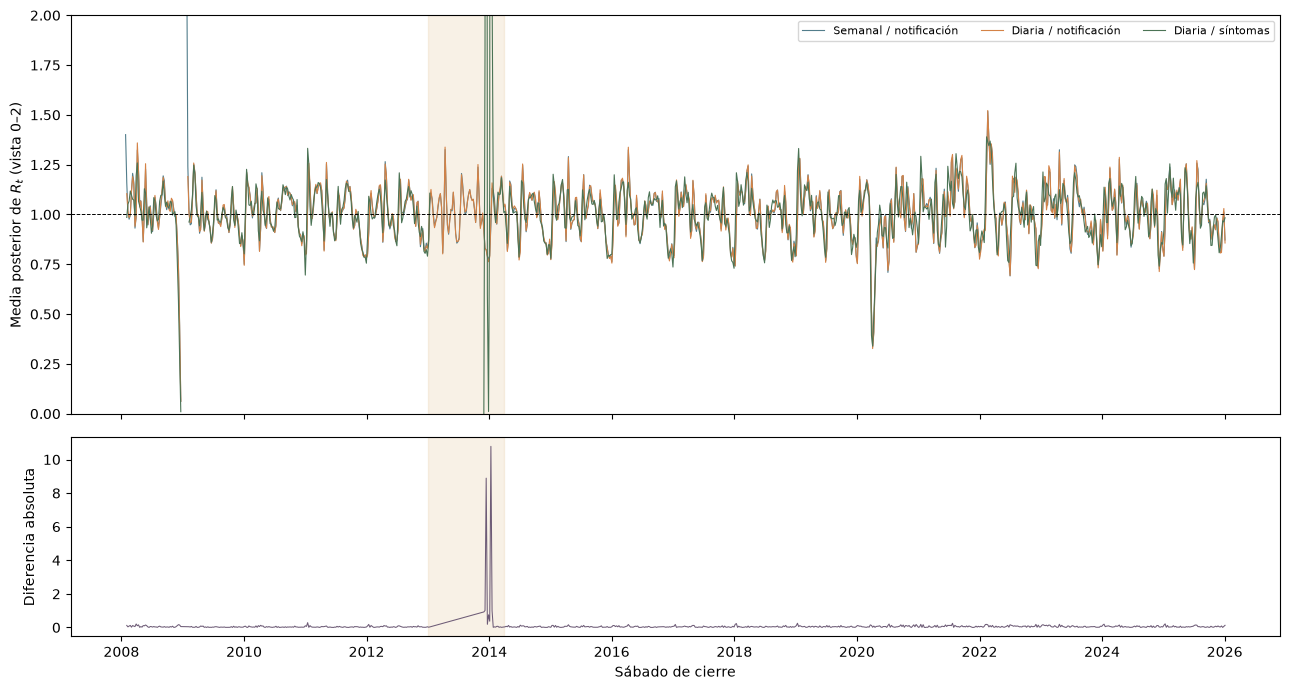

In [3]:
# Plot all three posterior means at the same epidemiological week endings.
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for suffix, label, color in (
    ("weekly", "Semanal / notificación", "#527d8b"),
    ("notification", "Diaria / notificación", "#d48246"),
    ("onset", "Diaria / síntomas", "#4b7355"),
):
    axes[0].plot(joined.date, joined[f"rt_{suffix}"], label=label, color=color, lw=0.8)
axes[0].axhline(1, color="black", ls="--", lw=0.7)
axes[0].set(ylabel="Media posterior de $R_t$ (vista 0–2)", ylim=(0, 2))
axes[0].legend(ncol=3, fontsize=8)
axes[1].plot(common.date, (common.rt_onset - common.rt_notification).abs(), color="#6d5b76", lw=0.75)
axes[1].set(ylabel="Diferencia absoluta", xlabel="Sábado de cierre")
for axis in axes:
    axis.axvspan(pd.Timestamp("2013-01-01"), pd.Timestamp("2014-03-31"), color="#e6c89d", alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Reloj de notificación frente a inicio de síntomas

Aquí sí usamos **todos los días comunes** de las dos rutas diarias, tanto en la serie completa como fuera de 2013 y el primer trimestre de 2014. La mediana y el percentil 95 de $|R_t^{\mathrm{INI\_SIN}}-R_t^{\mathrm{FEC\_NOT}}|$ describen desfases y diferencias de forma, pero **no identifican por sí solos su causa**. Las dos curvas se calculan con subconjuntos de registros diferentes cuando `INI_SIN` falta; no es un experimento que aísle únicamente el retraso de notificación.

También se muestra el ciclo por día de la semana en los conteos observados. Una menor variación por día de la semana es compatible con menor influencia del calendario administrativo, pero no demuestra que la curva de síntomas sea libre de artefactos.

In [4]:
matched = notification[["date", "notifications", "rt", "rt_lower_95", "rt_upper_95"]].merge(
    onset[["date", "cases", "rt", "rt_lower_95", "rt_upper_95"]],
    on="date", validate="one_to_one", suffixes=("_notification", "_onset")
).dropna(subset=["rt_notification", "rt_onset"])
matched["absolute_difference"] = (matched.rt_notification - matched.rt_onset).abs()
calendar_rows = []
for label, subset in (
    ("Todos los días comunes", matched),
    ("Fuera de 2013 y 2014 T1", matched.loc[~matched.date.between("2013-01-01", "2014-03-31")]),
):
    calendar_rows.append({
        "tramo": label, "días": len(subset),
        "diferencia absoluta mediana": subset.absolute_difference.median(),
        "percentil 95 de diferencia": subset.absolute_difference.quantile(.95),
    })
display(pd.DataFrame(calendar_rows).round(4))
day_names = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
weekday_rows = []
for source, column, label in ((notification, "notifications", "Notificación"), (onset, "cases", "Síntomas")):
    means = source.groupby(source.date.dt.dayofweek)[column].mean()
    for weekday, value in means.items():
        weekday_rows.append({"ruta": label, "día": day_names[weekday], "media de casos": value})
display(pd.DataFrame(weekday_rows).pivot(index="día", columns="ruta", values="media de casos").reindex(day_names).round(1))

,tramo,días,diferencia absoluta mediana,percentil 95 de diferencia
0,Todos los días comunes,6180,0.0390,0.1459
1,Fuera de 2013 y 2014 T1,6045,0.0389,0.1381


ruta,Notificación,Síntomas
día,,
lunes,220.0,200.2
martes,201.9,182.9
miércoles,181.1,175.4
jueves,177.5,171.6
viernes,192.7,176.3
sábado,242.5,173.6
domingo,88.7,190.6


## 4. Sensibilidad formal dentro de cada ruta diaria

Se recalculan cuatro alternativas frente a Simpson–14 días: Vally (media serial 13,1, DE 2,2), Lai (14,2, 1,3), Simpson–7 días y Simpson–21 días. En cada ruta se usa el mismo conteo, la misma previa y los días en que los **cinco** escenarios tienen posterior. La comparación entre rutas se presenta en columnas, pero **cada ruta tiene un conjunto de días evaluables distinto**.

La superposición de posteriores Gamma se mide mediante $BC=\int\sqrt{f_{\rm base}(r)f_{\rm alternativa}(r)}\,dr$, calculado analíticamente con `gammaln`: 1 significa distribuciones iguales. El 95 % es un umbral descriptivo. Para evaluar predicción retrospectiva al día siguiente, integramos la posterior Gamma del día $t$ en $I_{t+1}\mid R_t\sim\operatorname{Poisson}(R_t\Lambda_{t+1})$: resulta una binomial negativa con $n=\alpha_t$ y $p=\beta_t/(\beta_t+\Lambda_{t+1})$. Siguiendo el criterio APE de [Parag y Donnelly (2020)](https://doi.org/10.1371/journal.pcbi.1007990), sumamos las pérdidas $-\log P(I_{t+1})$ y restamos la pérdida de la base: $\Delta\mathrm{APE}<0$ favorece a la alternativa. En `INI_SIN`, los inicios se conocen retrospectivamente; esto **no es una predicción disponible en tiempo real**. La prueba de Wilcoxon pareada es exploratoria porque los días y las ventanas solapadas no son observaciones independientes.

Las inversiones y $\kappa$ se basan en las tres clases definidas arriba. Se verifica que la forma $1+\sum I_d$ y la tasa $0{,}2+\sum\Lambda_d$ reproduzcan la media y los cuantiles publicados.

In [5]:
SCENARIOS = {
    "Simpson, 14 días": (14.1, 2.4, 14),
    "Vally, 14 días": (13.1, 2.2, 14),
    "Lai, 14 días": (14.2, 1.3, 14),
    "Simpson, 7 días": (14.1, 2.4, 7),
    "Simpson, 21 días": (14.1, 2.4, 21),
}


def gamma_overlap(shape_a, rate_a, shape_b, rate_b):
    """Compute Bhattacharyya overlap of two Gamma densities in log space."""
    mean_shape = (shape_a + shape_b) / 2
    log_overlap = (
        gammaln(mean_shape) - (gammaln(shape_a) + gammaln(shape_b)) / 2
        + (shape_a * np.log(rate_a) + shape_b * np.log(rate_b)) / 2
        - mean_shape * np.log((rate_a + rate_b) / 2)
    )
    return np.exp(np.minimum(log_overlap, 0))


def route_sensitivity(source, count_column, estimator, route_label):
    """Reproduce within-route posterior overlap, predictive loss, and regime agreement."""
    raw = source[["date", "year", "week", count_column, "missing_week"]].copy()
    variants = {}
    parameters = {}
    for name, (serial_mean, serial_sd, window) in SCENARIOS.items():
        variant = estimator(raw, mean_si=serial_mean, sd_si=serial_sd, window_days=window)
        variants[name] = variant
        shape = 1 + variant[count_column].rolling(window, min_periods=window).sum()
        rate = 0.2 + variant.infectiousness.rolling(window, min_periods=window).sum()
        available = variant.rt.notna()
        np.testing.assert_allclose((shape / rate)[available], variant.rt[available], rtol=2e-7, atol=1e-7)
        np.testing.assert_allclose(gamma.ppf(.025, shape[available], scale=1 / rate[available]), variant.rt_lower_95[available], rtol=2e-7, atol=1e-7)
        np.testing.assert_allclose(gamma.ppf(.975, shape[available], scale=1 / rate[available]), variant.rt_upper_95[available], rtol=2e-7, atol=1e-7)
        parameters[name] = (shape.to_numpy(), rate.to_numpy())
    np.testing.assert_allclose(variants["Simpson, 14 días"].rt, source.rt, rtol=2e-7, atol=1e-7, equal_nan=True)
    common_indices = np.flatnonzero(np.logical_and.reduce([v.rt.notna().to_numpy() for v in variants.values()]))
    predictor_indices = common_indices[common_indices + 1 < len(source)]
    next_indices = predictor_indices + 1
    observed_next = source[count_column].to_numpy()[next_indices]
    valid = np.isfinite(observed_next) & (observed_next >= 0)
    for variant in variants.values():
        future_infectiousness = variant.infectiousness.to_numpy()[next_indices]
        valid &= np.isfinite(future_infectiousness) & (future_infectiousness > 0)
    predictor_indices = predictor_indices[valid]
    next_indices = predictor_indices + 1
    observed_next = source[count_column].to_numpy()[next_indices]
    assert np.all(observed_next == np.floor(observed_next))
    losses = {}
    for name, variant in variants.items():
        shape, rate = parameters[name]
        future_infectiousness = variant.infectiousness.to_numpy()[next_indices]
        probability = rate[predictor_indices] / (rate[predictor_indices] + future_infectiousness)
        losses[name] = -nbinom.logpmf(observed_next, shape[predictor_indices], probability)
        assert np.isfinite(losses[name]).all()
    base_name = "Simpson, 14 días"
    base_shape, base_rate = parameters[base_name]
    base_variant = variants[base_name]
    base_state = np.where(base_variant.rt_lower_95.to_numpy()[common_indices] > 1, 1,
                          np.where(base_variant.rt_upper_95.to_numpy()[common_indices] < 1, -1, 0))
    outside_problem = ~source.date.iloc[next_indices].between("2013-01-01", "2014-03-31").to_numpy()
    rows = []
    for name, variant in variants.items():
        shape, rate = parameters[name]
        overlap = gamma_overlap(base_shape[common_indices], base_rate[common_indices],
                                shape[common_indices], rate[common_indices])
        state = np.where(variant.rt_lower_95.to_numpy()[common_indices] > 1, 1,
                         np.where(variant.rt_upper_95.to_numpy()[common_indices] < 1, -1, 0))
        difference = losses[name] - losses[base_name]
        rows.append({
            "ruta": route_label, "escenario": name,
            "días posteriores": len(common_indices), "días predictivos": len(predictor_indices),
            "BC mediano %": 100 * np.median(overlap),
            "diferencia absoluta mediana de Rt": float(np.median(np.abs(variant.rt.to_numpy()[common_indices] - base_variant.rt.to_numpy()[common_indices]))),
            "días BC ≥ 0,95 %": 100 * np.mean(overlap >= .95),
            "inversiones estrictas IC 95 %": int(np.count_nonzero(base_state * state == -1)),
            "κ ponderado IC 95 %": quadratic_kappa(base_state, state),
            "ΔAPE total": float(difference.sum()),
            "p Wilcoxon nominal": np.nan if name == base_name else wilcoxon(difference, zero_method="wilcox", method="auto").pvalue,
            "días predictivos fuera de 2013 y 2014 T1": int(outside_problem.sum()),
            "ΔAPE fuera de 2013 y 2014 T1": float(difference[outside_problem].sum()),
        })
    return pd.DataFrame(rows), variants, common_indices, predictor_indices


notification_sensitivity, notification_variants, notification_common, notification_predictors = route_sensitivity(
    notification, "notifications", estimate_daily, "Notificación"
)
onset_sensitivity, onset_variants, onset_common, onset_predictors = route_sensitivity(
    onset, "cases", estimate_onset_rt, "Síntomas"
)
sensitivity = pd.concat([notification_sensitivity, onset_sensitivity], ignore_index=True)
shown_sensitivity = sensitivity.round(3)
shown_sensitivity["p Wilcoxon nominal"] = sensitivity["p Wilcoxon nominal"].map(
    lambda value: "—" if pd.isna(value) else f"{value:.2e}"
)
display(shown_sensitivity)

,ruta,escenario,días posteriores,días predictivos,BC mediano %,diferencia absoluta mediana de Rt,"días BC ≥ 0,95 %",inversiones estrictas IC 95 %,κ ponderado IC 95 %,ΔAPE total,p Wilcoxon nominal,días predictivos fuera de 2013 y 2014 T1,ΔAPE fuera de 2013 y 2014 T1
0,Notificación,"Simpson, 14 días",6493,6491,100.000,0.000,100.000,0,1.000,0.000,—,6036,0.000
1,Notificación,"Vally, 14 días",6493,6491,98.808,0.007,80.594,0,0.972,2050.596,2.88e-39,6036,1886.545
2,Notificación,"Lai, 14 días",6493,6491,99.568,0.004,94.486,0,0.980,-2988.755,5.73e-17,6036,-2874.906
3,Notificación,"Simpson, 7 días",6493,6491,66.940,0.047,13.153,145,0.737,-7243.290,5.99e-56,6036,-6437.358
4,Notificación,"Simpson, 21 días",6493,6491,71.010,0.033,17.942,108,0.804,1831.464,2.82e-08,6036,1627.919
5,Síntomas,"Simpson, 14 días",6159,6156,100.000,0.000,100.000,0,1.000,0.000,—,6029,0.000
6,Síntomas,"Vally, 14 días",6159,6156,99.028,0.006,84.202,0,0.968,1076.008,3.61e-57,6029,1082.994
7,Síntomas,"Lai, 14 días",6159,6156,99.746,0.003,97.987,0,0.984,16460.097,3.74e-03,6029,194.870
8,Síntomas,"Simpson, 7 días",6159,6156,74.200,0.041,15.376,94,0.749,-11776.160,7.30e-59,6029,-3065.370
9,Síntomas,"Simpson, 21 días",6159,6156,78.722,0.028,21.952,62,0.806,-737.126,9.98e-14,6029,1080.599


## 5. Auditoría del tramo de 2013 y alcance de las inferencias

El [cuaderno 06](06_rt_nacional_inicio_sintomas.ipynb) audita 2013: de 93.606 registros incluidos, 37.920 tienen `INI_SIN` interpretable (**40,51 %**). Sus 18 semanas sin casos fechados en 2013 son **semanas sin dato**, no semanas con cero casos. Una posterior extrema al reaparecer fechas no demuestra por sí misma un brote. La exclusión de 2013 y enero–marzo de 2014 es un **diagnóstico de sensibilidad definido por calidad de datos**, no una corrección de los casos faltantes. Las diferencias de APE dentro de cada ruta califican distintos conteos futuros; no deben restarse entre `FEC_NOT` e `INI_SIN` para proclamar un método superior.

Para precisar el efecto de 2013 en Lai, se separa su contribución a $\Delta$APE y se inspecciona si las mayores pérdidas coinciden con infectividad casi nula. Una asociación numérica no prueba que la cola serial más estrecha sea la única causa: también intervienen los saltos de cobertura, la ventana y el modelo Poisson.

In [6]:
base = sensitivity.loc[sensitivity.escenario.eq("Simpson, 14 días")]
lai = sensitivity.loc[sensitivity.escenario.eq("Lai, 14 días")].copy()
lai["contribución de 2013 y 2014 T1 a ΔAPE"] = lai["ΔAPE total"] - lai["ΔAPE fuera de 2013 y 2014 T1"]
display(lai[["ruta", "días predictivos", "días predictivos fuera de 2013 y 2014 T1",
             "ΔAPE total", "ΔAPE fuera de 2013 y 2014 T1", "contribución de 2013 y 2014 T1 a ΔAPE"]].round(2))
assert int(onset_sensitivity.iloc[0]["días posteriores"]) == 6159
assert int(onset_sensitivity.iloc[0]["días predictivos"]) == 6156
assert int(onset_sensitivity.iloc[0]["días predictivos fuera de 2013 y 2014 T1"]) == 6029
assert int(onset.loc[onset.date.dt.year.eq(2013), "cases"].isna().sum()) >= 18 * 7
print("Máximo Rₜ por síntomas:", round(onset.rt.max(), 4), "el", onset.loc[onset.rt.idxmax(), "date"].date())

,ruta,días predictivos,días predictivos fuera de 2013 y 2014 T1,ΔAPE total,ΔAPE fuera de 2013 y 2014 T1,contribución de 2013 y 2014 T1 a ΔAPE
2,Notificación,6491,6036,-2988.76,-2874.91,-113.85
7,Síntomas,6156,6029,16460.10,194.87,16265.23


Máximo Rₜ por síntomas: 17.0121 el 2013-12-12


In [7]:
# Locate the largest onset-route deviations instead of treating them as outbreaks.
extreme_rows = []
baseline_variant = onset_variants["Simpson, 14 días"]
for name, variant in onset_variants.items():
    if name == "Simpson, 14 días":
        continue
    distance = (variant.rt - baseline_variant.rt).abs()
    position = distance.idxmax()
    extreme_rows.append({
        "escenario": name,
        "fecha de máxima diferencia": variant.date.iloc[position].date(),
        "diferencia máxima de Rt": distance.iloc[position],
        "Rt base": baseline_variant.rt.iloc[position],
        "Rt alternativo": variant.rt.iloc[position],
        "infectividad base ese día": baseline_variant.infectiousness.iloc[position],
        "infectividad alternativa ese día": variant.infectiousness.iloc[position],
    })
display(pd.DataFrame(extreme_rows).round(3))

,escenario,fecha de máxima diferencia,diferencia máxima de Rt,Rt base,Rt alternativo,infectividad base ese día,infectividad alternativa ese día
0,"Vally, 14 días",2013-12-11,6.958,12.872,19.830,19.984,40.039
1,"Lai, 14 días",2013-12-12,98.192,17.012,115.204,47.374,6.179
2,"Simpson, 7 días",2013-12-09,242.479,4.628,247.107,1.392,1.392
3,"Simpson, 21 días",2013-12-12,15.267,17.012,1.745,47.374,47.374


## 6. Conclusiones comparativas

Las tablas anteriores son la fuente de los valores finales. La lectura debe separar tres preguntas: cuánto cambian las estimaciones al reconstruir días desde semanas, cuánto cambian al fechar por síntomas, y cuán sensibles son **dentro de una misma ruta** a intervalos seriales o ventanas alternativos. Una coincidencia de curvas no valida el supuesto de renovación, y un APE menor solo favorece la predicción retrospectiva del conteo usado por esa ruta.

In [8]:
def metric(route, scenario, field):
    """Read one value from the computed sensitivity table."""
    return sensitivity.loc[(sensitivity.ruta == route) & (sensitivity.escenario == scenario), field].iloc[0]

summary = pd.DataFrame([
    {"hallazgo": "Diferencia mediana diaria FEC_NOT–INI_SIN fuera de 2013 y 2014 T1",
     "valor": f"{calendar_rows[1]['diferencia absoluta mediana']:.4f}"},
    {"hallazgo": "BC mediano Vally / Lai con INI_SIN",
     "valor": f"{metric('Síntomas', 'Vally, 14 días', 'BC mediano %'):.2f} % / {metric('Síntomas', 'Lai, 14 días', 'BC mediano %'):.2f} %"},
    {"hallazgo": "ΔAPE de Lai con INI_SIN: total / fuera del tramo problemático",
     "valor": f"{metric('Síntomas', 'Lai, 14 días', 'ΔAPE total'):.1f} / {metric('Síntomas', 'Lai, 14 días', 'ΔAPE fuera de 2013 y 2014 T1'):.1f}"},
    {"hallazgo": "ΔAPE de la ventana de 7 días con INI_SIN fuera del tramo",
     "valor": f"{metric('Síntomas', 'Simpson, 7 días', 'ΔAPE fuera de 2013 y 2014 T1'):.1f}"},
])
display(summary)

,hallazgo,valor
0,Diferencia mediana diaria FEC_NOT–INI_SIN fuer...,0.0389
1,BC mediano Vally / Lai con INI_SIN,99.03 % / 99.75 %
2,ΔAPE de Lai con INI_SIN: total / fuera del tra...,16460.1 / 194.9
3,ΔAPE de la ventana de 7 días con INI_SIN fuera...,-3065.4


### Interpretación

1. **Comparación de las tres rutas.** En **885 semanas** con tres estimaciones, la diferencia absoluta mediana es **0,0063** entre las dos rutas de notificación, **0,0372** entre semanal/notificación y diaria/síntomas, y **0,0362** entre ambas rutas diarias al tomar solo sábados. Las dos rutas de notificación no presentan inversiones estrictas de IC 95 % en esas semanas; las comparaciones con síntomas tienen **16** y **15**, respectivamente. La vista superior del gráfico limita el eje a $R_t=0$–$2$ para hacer legible el régimen habitual; el valor extremo de **17,01** por síntomas en diciembre de 2013 queda fuera de esa escala, pero permanece en el CSV y en la auditoría de la sección 5.

2. **Cambio de fecha a escala diaria.** En **6.180 días** con ambas posteriores, la diferencia absoluta mediana entre `FEC_NOT` e `INI_SIN` es **0,0390**; fuera de 2013–2014 T1, en **6.045 días**, es **0,0389** y su percentil 95 es **0,1381**. Esos cambios combinan desplazamiento de fecha y cobertura desigual de `INI_SIN`; no se pueden atribuir enteramente a la demora de notificación. El calendario muestra medias de **88,7** notificaciones en domingo frente a **242,5** en sábado, mientras que los inicios consignados van de **171,6** en jueves a **200,2** en lunes. La serie de síntomas es más regular por día de la semana, pero puede conservar otros sesgos de registro.

3. **Intervalo serial y régimen.** Los $BC$ medianos de Vally y Lai frente a Simpson–14 días son **98,81 %** y **99,57 %** con notificaciones, y **99,03 %** y **99,75 %** con síntomas. No hay inversiones estrictas de crecimiento a descenso entre estas variantes en sus respectivos días comparables: **6.493** para notificaciones y **6.159** para síntomas. Con síntomas, los $\kappa$ ponderados son **0,968** y **0,984**. Esto apoya estabilidad *relativa* frente a esos intervalos bibliográficos; no prueba igualdad de las posteriores ni valida el intervalo serial en Colombia.

4. **Duración de la ventana.** Con `INI_SIN`, la ventana de 7 días tiene $BC$ mediano **74,20 %**, $\kappa=0,749$ y **94** inversiones estrictas frente a 14 días; la de 21 días tiene **78,72 %**, $\kappa=0,806$ y **62**. Con `FEC_NOT`, los respectivos $BC$ son **66,94 %** y **71,01 %**, con **145** y **108** inversiones. En ambas rutas, variar la ventana afecta más la posterior que sustituir Simpson por Vally o Lai.

5. **APE y defecto de 2013.** En la ruta de síntomas, Lai pasa de $\Delta$APE **+16.460,10** sobre **6.156** predicciones a **+194,87** sobre **6.029** fuera de 2013–2014 T1: los **127 días** excluidos aportan **+16.265,23**. Las mayores diferencias de media aparecen en diciembre de 2013: Lai se aparta hasta **98,19** de la base el 12 de diciembre, cuando su infectividad calculada ese día es **6,18** frente a **47,37** con Simpson; la ventana de 7 días se aparta hasta **242,48** el 9 de diciembre. Estos cálculos muestran sensibilidad a los huecos y a los pesos seriales, pero no prueban que la cola más estrecha de Lai sea la única causa. Fuera del tramo, Simpson–14 días tiene menor APE que Vally (**+1.082,99**) y Lai (**+194,87**) **entre los tres intervalos ensayados**. Entre las ventanas, Simpson–7 días conserva menor APE que la base (**−3.065,37**) y Simpson–21 días es peor (**+1.080,60**). En `FEC_NOT`, Lai y la ventana de 7 días tienen $\Delta$APE negativos (**−2.988,76** y **−7.243,29**). Por ello, los datos no establecen que 14 días sea la duración óptima ni que Simpson sea biológicamente superior.

**Límites:** Los IC son condicionales al modelo Poisson–Gamma. Cada APE puntúa el conteo específico de su propia ruta: no son pérdidas enfrentadas sobre un mismo objetivo. La prueba de Wilcoxon es nominal por dependencia temporal; `INI_SIN` se conoce retrospectivamente. Una comparación de calidad predictiva entre rutas necesitaría un objetivo común independiente, disponibilidad según fecha real de reporte y un modelo explícito del retraso y los faltantes.